# Reward Design and Generator Inductive Bias in Reaction-GFlowNet Molecular Generation

## Abstract

Notebook 14 compared potency signals within a single generator. This notebook moves the comparison to the generator itself. A reaction-based GFlowNet (RGFN), which assembles molecules from purchasable building blocks and reaction templates, is run on EGFR under three rewards that share the same pessimistic lower-confidence-bound form and the same QED, synthetic-accessibility and logD quality terms, and differ only in the potency signal: a ligand-based QSAR pIC50, a structure-based docking surrogate, and docking with the quality guards. Each arm is run over five independent seeds, and every generated population is re-docked with smina for an independent 3D readout. REINVENT is added as a second generator at the matched ligand objective. Single-objective docking drifts toward large, lipophilic, low-efficiency molecules; the quality guards pull QED and logP back toward drug-like space while increasing scaffold diversity. The 2D surrogate stays faithful to the true oracle in the bulk and saturates only at the top, so the drift is an oracle-versus-reality effect rather than pose-level surrogate hacking. Ligand efficiency inverts the raw-affinity ranking and exposes the size bias. At a matched objective, RGFN and REINVENT occupy different chemical regions, showing that the generator's action space sets the reachable region as much as the reward does. All effects are stable across the five seeds.

## Introduction

Notebook 13 established that a docking reward over-optimizes toward molecular obesity, and notebook 14 mapped the trade-offs between potency signals inside one generator. Both held the generator fixed. The open question is whether those conclusions transfer to a different generator, and whether the generator or the reward controls the outcome. RGFN answers the first part by construction: it builds molecules from a fixed library of fragments and reaction templates, so every generated molecule carries an explicit synthetic route, unlike the token-level generation of REINVENT. This notebook runs RGFN under the same reward family as notebook 14, validates each population on an independent 3D oracle, and compares RGFN against REINVENT at a matched objective to separate the effect of the reward from the effect of the generator.

## Methods

Three RGFN reward objectives are compared on EGFR. All share two fixed quality terms, drug-likeness (QED) and synthetic accessibility, combined with the potency term and a logD window by a renormalized geometric mean, and all score potency as a pessimistic lower confidence bound μ − λσ. They differ only in the potency signal: the QSAR pIC50 ensemble (`activity`), the docking surrogate (`dock`), and the docking surrogate kept with the same guards (`dock,qed,sa,logd`). The docking surrogate is a fast 2D Gaussian-process approximation of smina, used as the reward so that it can be queried on every generated molecule; the full 3D shape block is dropped, which costs under 0.01 R² on the held-out set.

RGFN builds a molecule as a sequence of chemical reactions rather than atom by atom. Generation starts from a purchasable building block, and at each step the forward policy either applies a reaction template to the current intermediate with a second block, or stops. Every trajectory is thus a short synthetic route, and every terminal molecule is synthesizable by construction from the 350-block, 66-reaction library. The policy is trained with the trajectory-balance objective so that terminal molecules are sampled with probability proportional to their reward R = exp(β·desirability), not driven to a single maximum. This proportional sampling is what makes the generator cover many scaffolds instead of collapsing onto one, and it is the property exploited throughout this notebook.

Each objective is run over five independent RGFN seeds (350 building blocks, 66 reactions, 3000 iterations, trajectory-balance loss), and the final cumulative mode set of each run is kept. REINVENT 4 baselines are added at the matched ligand objective and at a docking objective (RNN prior on PubChem, DAP, σ = 128, 190 steps, batch 64), taking the final-stage deduplicated molecules. Every molecule is profiled on QED, logP, molecular weight, heavy-atom count, synthetic accessibility, novelty (maximum Tanimoto to the training actives), and per-run Bemis–Murcko scaffold diversity. To validate binding independently of the training surrogate, the top-50 of each arm are re-docked with smina in 3D, and reported both as raw affinity and as ligand efficiency (affinity per heavy atom).

In [1]:
import glob, os, sys
import joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, mannwhitneyu, spearmanr
from rdkit import Chem
from rdkit.Chem import Descriptors, QED, RDConfig, AllChem, DataStructs
from rdkit.Chem.Scaffolds import MurckoScaffold
sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score")); import sascorer
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

RGFN      = "/mnt/c/Users/coure/RGFN"
REPO      = "/mnt/c/Users/coure/Projects/cheminformatics"
REINVENT4 = "/home/couret/REINVENT4"
FIGDIR    = f"{REPO}/figures"; os.makedirs(FIGDIR, exist_ok=True)

ARMS = {"QSAR multi-obj": "rgfn_scorer_qsar",
        "Docking only":   "rgfn_scorer_dock_only",
        "Docking multi-obj": "rgfn_scorer_dock_multi"}

# consistent, colorblind-safe palette (Okabe-Ito) shared by ALL figures
COLORS = {"QSAR multi-obj": "#0072B2", "Docking only": "#D55E00",
          "Docking multi-obj": "#009E73", "REINVENT full (ligand)": "#CC79A7",
          "REINVENT docking": "#E69F00"}

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 12, "axes.labelsize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
})

In [2]:
def enrich(df):
    """Recompute all descriptors from RDKit mols so every population is comparable."""
    df = df.copy()
    df["MW"]    = df["mol"].apply(Descriptors.MolWt)
    df["cLogP"] = df["mol"].apply(Descriptors.MolLogP)
    df["TPSA"]  = df["mol"].apply(Descriptors.TPSA)
    df["HAC"]   = df["mol"].apply(lambda m: m.GetNumHeavyAtoms())
    df["QED"]   = df["mol"].apply(QED.qed)
    df["SA"]    = df["mol"].apply(sascorer.calculateScore)
    return df

def n_scaffolds(df):
    return len({MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in df["mol"]})

def profile(pops):
    rows = []
    for name, df in pops.items():
        if df is None or not len(df): continue
        ns = n_scaffolds(df)
        rows.append(dict(population=name, n=len(df), n_scaffolds=ns,
            scaffold_ratio=ns/len(df), MW=df["MW"].median(),
            cLogP=df["cLogP"].median(), TPSA=df["TPSA"].median(),
            QED=df["QED"].median(), SA=df["SA"].median()))
    return pd.DataFrame(rows).set_index("population").round(3)

def kde_plot(ax, pops, col, xlabel):
    for name, df in pops.items():
        if df is None or len(df) < 5: continue
        x = df[col].dropna().values
        if len(x) < 5 or np.ptp(x) == 0: continue
        k = gaussian_kde(x); xs = np.linspace(x.min(), x.max(), 200)
        c = COLORS.get(name, "gray")
        ax.plot(xs, k(xs), color=c, lw=1.8, label=name)
        ax.fill_between(xs, k(xs), color=c, alpha=0.15)
    ax.set_xlabel(xlabel); ax.set_ylabel("density")

## Results

Reward design controls the generated distribution, and the effect is large relative to run-to-run noise (Figure 1). Docking-only produces the least drug-like and most lipophilic molecules (median QED 0.26, cLogP 3.71), the quality guards recover them (QED 0.37, cLogP 3.07), and the ligand-based QSAR reward sits in the same drug-like range (QED 0.36, cLogP 2.67). Molecular weight stays high in all arms (509 to 540 g/mol), set by the fragment-assembly action space. Inter-seed standard deviations are an order of magnitude smaller than these gaps (for example QED 0.264 ± 0.005 versus 0.374 ± 0.004), so the differences are not seed artefacts. All three arms generate near-unique scaffolds and molecules below the 0.4 novelty threshold (Figure 2), i.e. genuinely new chemotypes rather than memorized actives.

The independent 3D re-docking reframes the ranking (Figure 3). Docking-only reaches the best raw affinity (median −9.75 kcal/mol) but the worst ligand efficiency (0.257 kcal/mol per atom), while the ligand-based arm reaches the weakest raw affinity (−7.8) yet the best per-atom efficiency (0.355): the docking-only advantage is size-driven, not genuine potency. The surrogate ranks the bulk correctly but saturates near μ ≈ 10, where docking-only concentrates (Spearman ρ 0.25 versus 0.43 for the guarded arm), so the drift is an oracle-versus-reality effect, not pose-level surrogate hacking.

At a matched ligand objective, the two generators land in different regions (Figure 4). With the same QED and SA terms in both rewards, RGFN generates larger, lower-QED, synthesis-constrained molecules (MW ≈ 510, QED ≈ 0.35) while REINVENT generates compact, high-QED molecules (MW ≈ 287, QED ≈ 0.82). The generator's inductive bias therefore sets the reachable region as much as the reward does.

In [3]:
def seed_runs(run_name, last=5):
    out = []
    for d in sorted(glob.glob(f"{RGFN}/experiments/{run_name}/*")):
        files = glob.glob(f"{d}/modes/modes_*.xlsx")
        if not files: continue
        files.sort(key=lambda p: int(p.split('_')[-1].split('.')[0]))
        if int(files[-1].split('_')[-1].split('.')[0]) < 2000:     
            continue
        df = pd.read_excel(files[-1]).dropna(subset=["SMILES"])
        df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
        df = df[df["mol"].notnull()].reset_index(drop=True)
        if len(df): out.append(enrich(df))
    return out[-last:]                                             

data_seeds = {name: seed_runs(rn) for name, rn in ARMS.items()}    
data = {name: (pd.concat(r, ignore_index=True) if r else None)     
        for name, r in data_seeds.items()}
for name in ARMS:
    print(f"{name:20s}: {len(data_seeds[name])} seeds | {0 if data[name] is None else len(data[name])} pooled modes")

QSAR multi-obj      : 5 seeds | 23645 pooled modes
Docking only        : 5 seeds | 9787 pooled modes
Docking multi-obj   : 5 seeds | 16553 pooled modes


In [4]:
def load_reinvent(pattern, last=20):
    """Final-stage, deduplicated, scored molecules from REINVENT CSV(s)."""
    dfs = []
    for f in glob.glob(pattern):
        d = pd.read_csv(f)
        d = d[(d["step"] >= d["step"].max() - last) & (d["Score"] > 0)]
        dfs.append(d[["SMILES", "Score"]])
    if not dfs: return None
    df = pd.concat(dfs, ignore_index=True).drop_duplicates("SMILES").reset_index(drop=True)
    df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
    return enrich(df[df["mol"].notnull()].reset_index(drop=True))

rein = {
    "REINVENT full (ligand)": load_reinvent(f"{REINVENT4}/ablation_runs/abl_full_s*_1.csv"),
    "REINVENT docking":       load_reinvent(f"{REINVENT4}/dock_runs/exp_al_s0_final_1.csv"),
}
for name, df in rein.items():
    print(f"{name:26s}: {0 if df is None else len(df):5d} molecules")

REINVENT full (ligand)    :  6307 molecules
REINVENT docking          :  1289 molecules


In [5]:
profile(data)

,n,n_scaffolds,scaffold_ratio,MW,cLogP,TPSA,QED,SA
population,,,,,,,,
QSAR multi-obj,23645,21177,0.896,508.627,2.671,125.78,0.355,3.722
Docking only,9787,9728,0.994,539.608,3.710,137.57,0.264,3.596
Docking multi-obj,16553,15939,0.963,513.664,3.069,122.21,0.374,3.611


In [6]:
def seed_table(runs):
    return pd.DataFrame([dict(
        n_modes=len(df), MW=df.MW.median(), cLogP=df.cLogP.median(),
        QED=df.QED.median(), SA=df.SA.median(), scaf_ratio=n_scaffolds(df)/len(df)
    ) for df in runs])

seed_stats = {name: seed_table(r) for name, r in data_seeds.items()}
pd.DataFrame([
    pd.Series({c: f"{t[c].mean():.3f} ± {t[c].std():.3f}" for c in t.columns}, name=name)
    for name, t in seed_stats.items()
])

,n_modes,MW,cLogP,QED,SA,scaf_ratio
QSAR multi-obj,4729.000 ± 75.067,508.643 ± 0.725,2.673 ± 0.044,0.355 ± 0.004,3.722 ± 0.005,0.939 ± 0.002
Docking only,1957.400 ± 31.754,539.966 ± 1.454,3.710 ± 0.038,0.264 ± 0.005,3.595 ± 0.004,0.999 ± 0.000
Docking multi-obj,3310.600 ± 71.150,514.188 ± 1.171,3.070 ± 0.028,0.374 ± 0.004,3.612 ± 0.014,0.984 ± 0.002


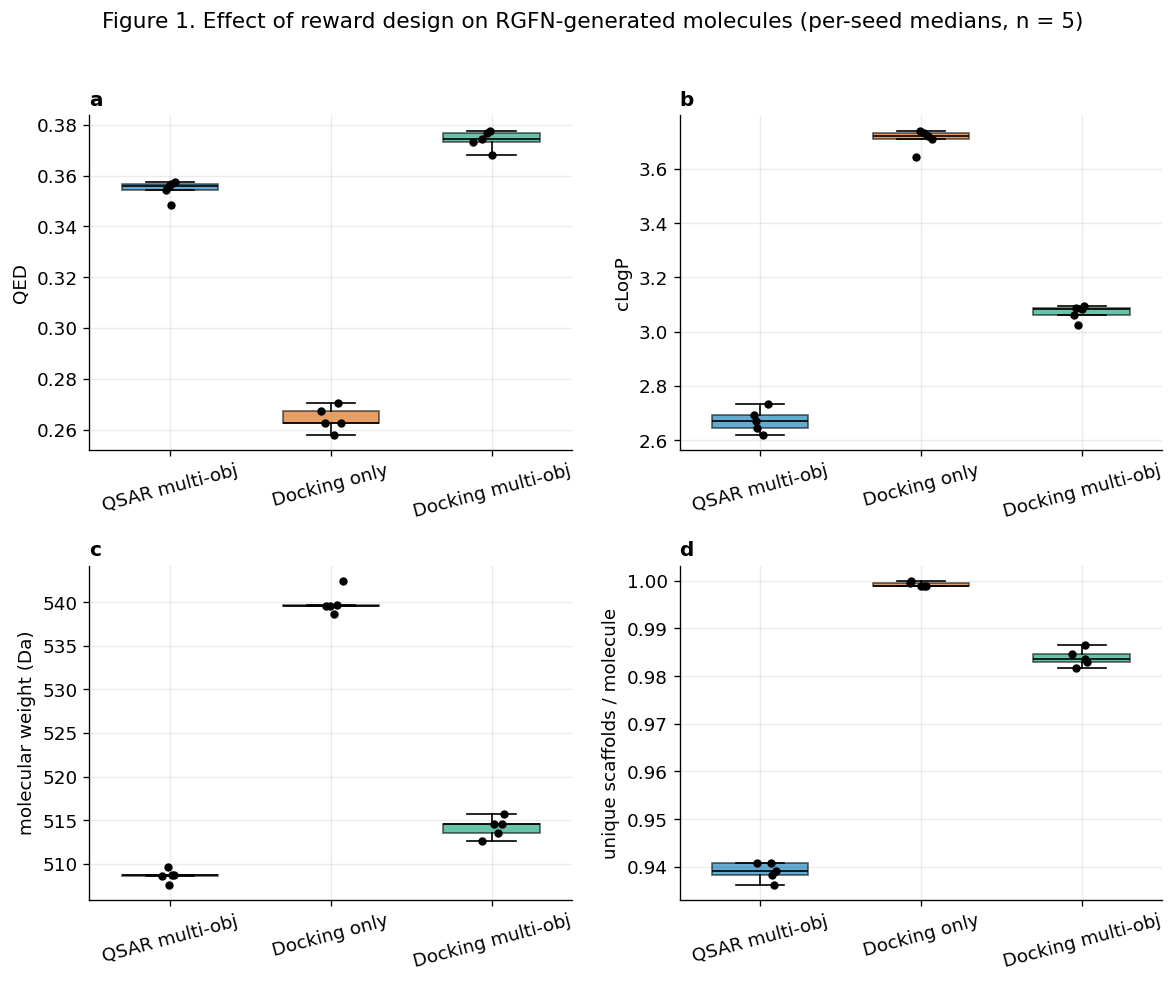

In [7]:
# === Figure 1 — effect of reward design (per-seed medians, n=5) ===
arms = list(ARMS); rng = np.random.default_rng(0)
panels = [("QED","a","QED"), ("cLogP","b","cLogP"),
          ("MW","c","molecular weight (Da)"), ("scaf_ratio","d","unique scaffolds / molecule")]
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for A, (col, tag, lab) in zip(ax.ravel(), panels):
    bp = A.boxplot([seed_stats[n][col].values for n in arms], tick_labels=arms,
                   patch_artist=True, widths=0.6, showfliers=False)
    for patch, n in zip(bp["boxes"], arms): patch.set_facecolor(COLORS[n]); patch.set_alpha(0.6)
    for med in bp["medians"]: med.set_color("black")
    for i, n in enumerate(arms):
        v = seed_stats[n][col].values
        A.scatter(rng.normal(i+1, 0.05, len(v)), v, s=16, color="k", zorder=3)
    A.set_ylabel(lab); A.set_title(tag, loc="left", fontweight="bold"); A.tick_params(axis="x", rotation=15)
fig.suptitle("Figure 1. Effect of reward design on RGFN-generated molecules (per-seed medians, n = 5)",
             y=1.02, fontsize=13)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb15_fig1_reward_design.png", dpi=200, bbox_inches="tight"); plt.show()

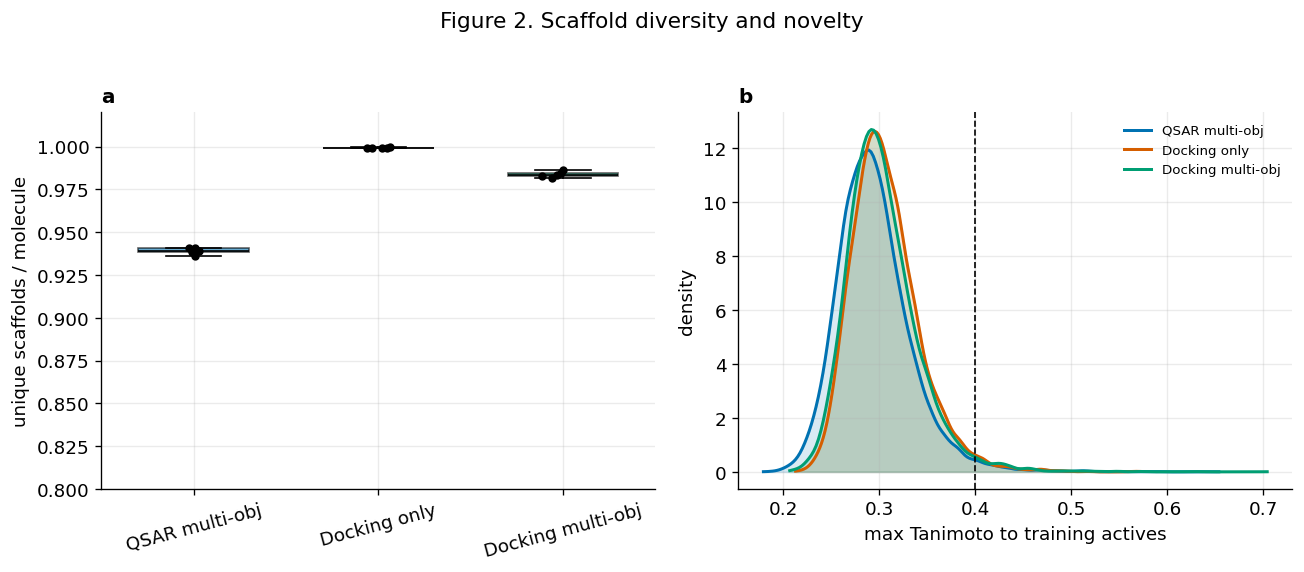

In [8]:
# novelty (max Tanimoto to training actives) on pooled molecules
ref = joblib.load(f"{REPO}/models/train_smiles.joblib")
ref_fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, 2048)
           for s in ref if (m := Chem.MolFromSmiles(s)) is not None]
def max_sim(mol):
    return max(DataStructs.BulkTanimotoSimilarity(AllChem.GetMorganFingerprintAsBitVect(mol,2,2048), ref_fps))
for df in data.values():
    if df is not None and len(df): df["novelty_sim"] = df["mol"].apply(max_sim)

# === Figure 2 — diversity and novelty ===
arms = list(ARMS); rng = np.random.default_rng(0)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.6))
bp = a.boxplot([seed_stats[n]["scaf_ratio"].values for n in arms], tick_labels=arms,
               patch_artist=True, widths=0.6, showfliers=False)
for patch, n in zip(bp["boxes"], arms): patch.set_facecolor(COLORS[n]); patch.set_alpha(0.6)
for med in bp["medians"]: med.set_color("black")
for i, n in enumerate(arms):
    v = seed_stats[n]["scaf_ratio"].values; a.scatter(rng.normal(i+1,.05,len(v)), v, s=16, color="k", zorder=3)
a.set_ylabel("unique scaffolds / molecule"); a.set_ylim(0.8, 1.02)
a.set_title("a", loc="left", fontweight="bold"); a.tick_params(axis="x", rotation=15)
for n in arms:
    kde_plot(b, {n: data[n]}, "novelty_sim", "max Tanimoto to training actives")
b.axvline(0.4, ls="--", c="k", lw=1); b.set_title("b", loc="left", fontweight="bold"); b.legend(fontsize=8)
fig.suptitle("Figure 2. Scaffold diversity and novelty", y=1.03, fontsize=13)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb15_fig2_diversity_novelty.png", dpi=200, bbox_inches="tight"); plt.show()

In [9]:
TOPK = 50
tosave = {"qsar": data["QSAR multi-obj"], "dock_only": data["Docking only"],
          "dock_multi": data["Docking multi-obj"], "reinvent_dock": rein["REINVENT docking"]}
for key, df in tosave.items():
    if df is None or not len(df): continue
    score_col = "Reward" if "Reward" in df else "Score"
    top = df.sort_values(score_col, ascending=False).drop_duplicates("SMILES").head(TOPK)
    top["SMILES"].to_csv(f"{REPO}/dock_seed/redock_{key}.smi", index=False, header=False)
    print(f"{key:14s}: {len(top)} SMILES written")

qsar          : 50 SMILES written
dock_only     : 50 SMILES written
dock_multi    : 50 SMILES written
reinvent_dock : 50 SMILES written


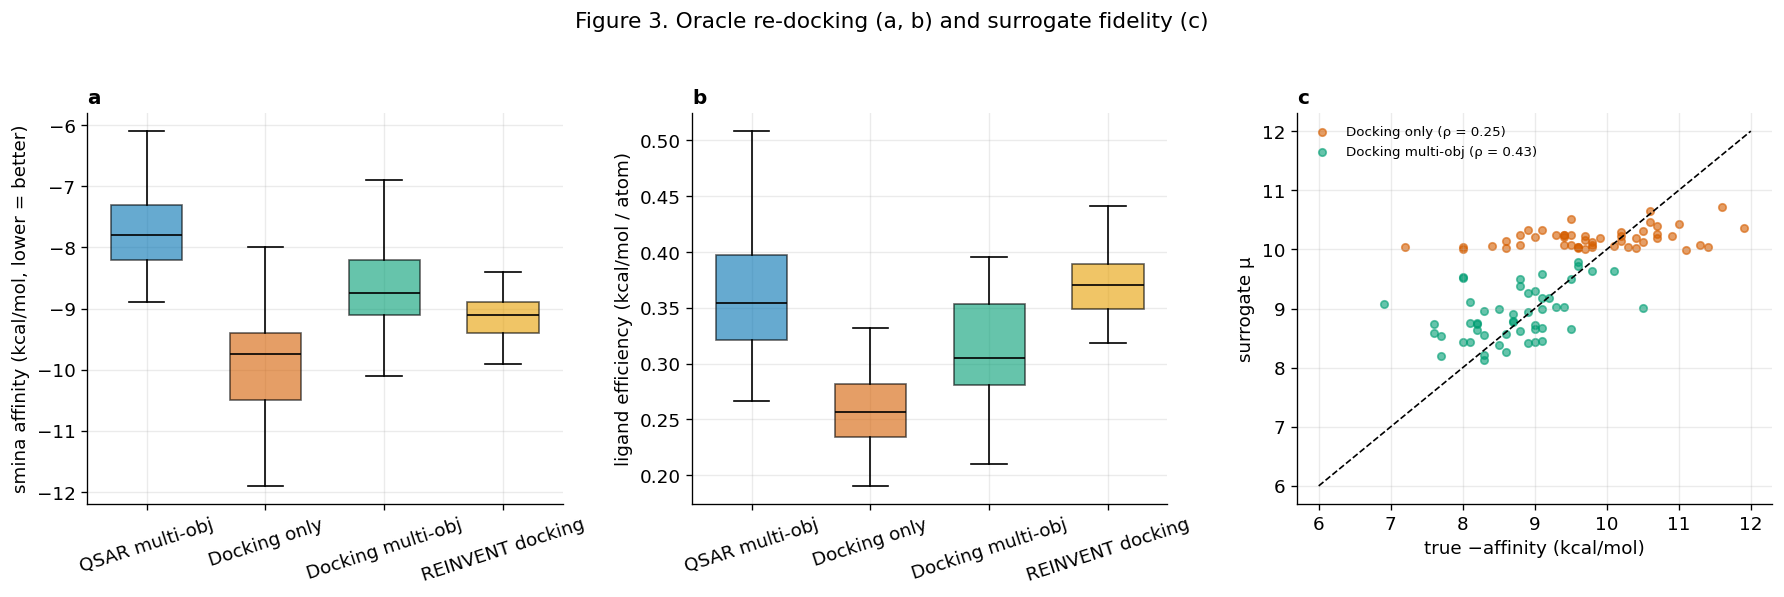

In [10]:
import glob
# --- (re)build `true` from the EGFR re-docking outputs ---
LABEL = {"qsar":"QSAR multi-obj", "dock_only":"Docking only",
         "dock_multi":"Docking multi-obj", "reinvent_dock":"REINVENT docking"}
true = {}
for f in sorted(glob.glob(f"{REPO}/dock_seed/redock_*_out.csv")):
    key = f.split("redock_")[1].replace("_out.csv", "")
    out = pd.read_csv(f).dropna(subset=["affinity"]).copy()
    out["hac"] = out["smiles"].apply(lambda s: (m := Chem.MolFromSmiles(s)) and m.GetNumHeavyAtoms())
    out["LE_true"] = -out["affinity"] / out["hac"]
    true[LABEL.get(key, key)] = out
    
# suppose: dict `true` déjà chargé depuis les redock_*_out.csv
sys.path.append(REPO); os.environ["DOCK_2D"] = "1"
from refit_surrogate_2d import load_surrogate_2d
pred = load_surrogate_2d()

# === Figure 3 — oracle re-docking (a, b) and surrogate fidelity (c) ===
order = [n for n in COLORS if n in true]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
for A, col, lab, tag in [(ax[0], "affinity", "smina affinity (kcal/mol, lower = better)", "a"),
                         (ax[1], "LE_true", "ligand efficiency (kcal/mol / atom)", "b")]:
    bp = A.boxplot([true[n][col] for n in order], tick_labels=order, patch_artist=True, widths=0.6, showfliers=False)
    for patch, n in zip(bp["boxes"], order): patch.set_facecolor(COLORS[n]); patch.set_alpha(0.6)
    for med in bp["medians"]: med.set_color("black")
    A.set_ylabel(lab); A.set_title(tag, loc="left", fontweight="bold"); A.tick_params(axis="x", rotation=18)
C = ax[2]
for n in ["Docking only", "Docking multi-obj"]:
    if n not in true: continue
    out = true[n]; mu, _ = pred(out["smiles"].tolist())
    rho = spearmanr(-out["affinity"], mu).correlation
    C.scatter(-out["affinity"], mu, s=20, alpha=0.6, color=COLORS[n], label=f"{n} (ρ = {rho:.2f})")
C.plot([6, 12], [6, 12], "k--", lw=1)
C.set_xlabel("true −affinity (kcal/mol)"); C.set_ylabel("surrogate μ")
C.set_title("c", loc="left", fontweight="bold"); C.legend(fontsize=8)
fig.suptitle("Figure 3. Oracle re-docking (a, b) and surrogate fidelity (c)", y=1.03, fontsize=13)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb15_fig3_oracle.png", dpi=200, bbox_inches="tight"); plt.show()

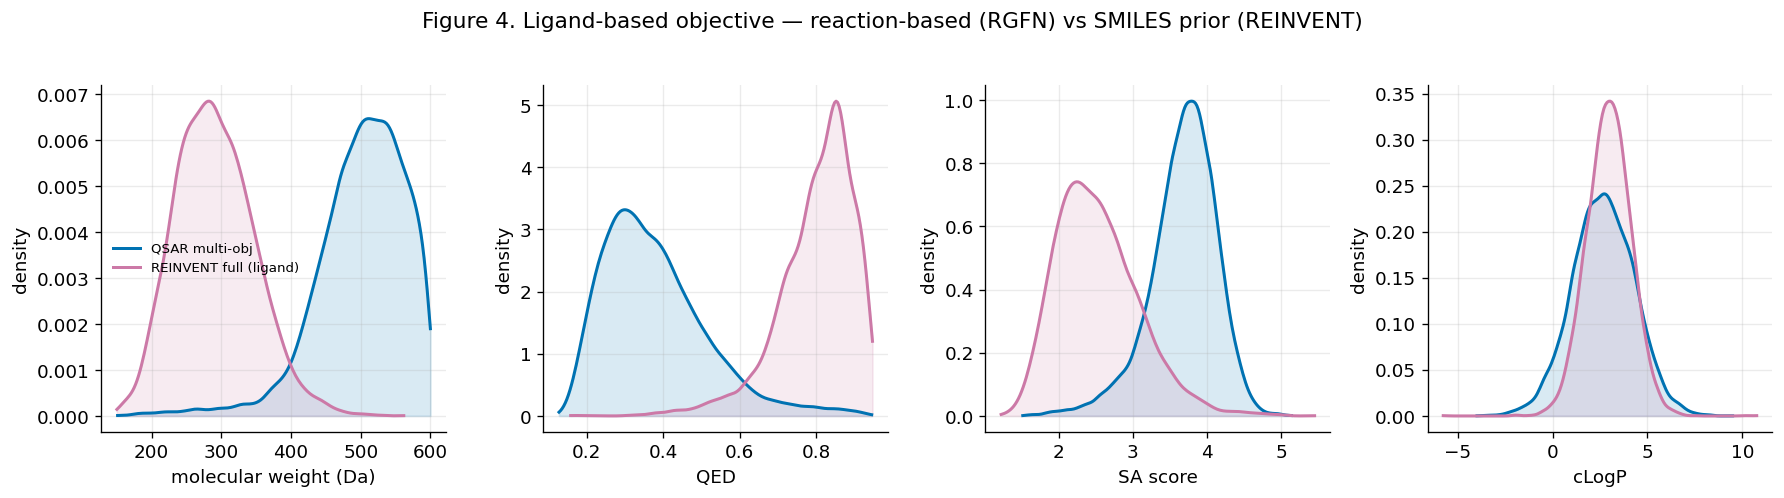

In [11]:
comp = {"QSAR multi-obj": data["QSAR multi-obj"],
        "REINVENT full (ligand)": rein["REINVENT full (ligand)"]}
metrics = [("MW", "molecular weight (Da)"), ("QED", "QED"),
           ("SA", "SA score"), ("cLogP", "cLogP")]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (col, lab) in zip(axes, metrics):
    kde_plot(ax, comp, col, lab)
axes[0].legend(fontsize=8)
fig.suptitle("Ligand-based objective — reaction-based (RGFN) vs SMILES prior (REINVENT)",
             y=1.03, fontsize=13)
fig.suptitle("Figure 4. Ligand-based objective — reaction-based (RGFN) vs SMILES prior (REINVENT)",
             y=1.03, fontsize=13)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/nb15_fig4_rgfn_vs_reinvent.png"); plt.show()

## Discussion

The comparison draws a consistent map. A structure-based reward buys docking score but inflates size and lipophilicity, and the pathology is oracle-versus-reality rather than surrogate hacking, since the surrogate held in the bulk. Quality guards redirect the optimizer at roughly 1 kcal/mol of raw affinity and, unlike the single diluted logD term of notebook 14, do shift the distribution because QED and SA act together. Ligand efficiency remains the metric that exposes the size bias, inverting the raw-affinity ranking. Finally, the generator matters as much as the reward: at a matched objective, action-space bias alone separates RGFN from REINVENT.

These results are bounded by the usual caveats. Docking is an imperfect and itself size-biased oracle. The RGFN–REINVENT docking comparison is not controlled for information access, because the REINVENT docking run used active learning against the true smina oracle whereas RGFN optimized only the 2D surrogate; it is reported as such. Five seeds give low statistical power, the aggregate reward is not comparable in absolute terms across generators, and no molecule was validated experimentally. Selectivity against the HER2 anti-target is treated separately in notebook 16.

## Conclusion

Within a synthesis-aware generator, the reward still sets the failure mode: a lone docking objective inflates size and lipophilicity, and the guards that work are the ones acting jointly (QED and SA), not a single diluted term. The honest ranking metric is ligand efficiency, which reverses the raw-affinity order and marks docking-only as the least efficient arm. Across generators, the action space weighs as much as the reward: at a matched objective, RGFN and REINVENT reach different chemical regions, RGFN larger and synthesis-constrained, REINVENT compact and drug-like. No single scalar objective and no single generator yields a lead-like population on its own; the usable region is a balanced multi-objective within a drug-like size window, pursued with a generator whose bias matches that window. Selectivity against the HER2 anti-target is taken up in notebook 16.